# Основы нейронных сетей — Практика: forward pass руками (2-слойный MLP на NumPy)

**Модуль 06 (Deep Learning), Тема 01.** Полная ручная реализация прямого прохода (`forward pass`), функций активации, численно устойчивого `Softmax`, функции потерь `Cross-Entropy` (`LogSumExp`) и проверки аналитических градиентов для двухслойного перцептрона (`4 -> 6 -> 3`) на чистом `NumPy` без использования `PyTorch` и `TensorFlow`.

**Структура ноутбука:**
1. **Постановка задачи и архитектура 2-слойного MLP (`4 -> 6 -> 3`):** формирование мини-батча `X (5, 4)`, меток `y_true (5,)`, весов `W1, b1, W2, b2` и подсчёт обучаемых параметров (`51`).
2. **Нейрон и полносвязный слой (`z = x @ W + b`):** пошаговое скалярное вычисление на чистом Python, векторизация на батче, механика `NumPy broadcasting` и сравнение с конвенцией хранения весов в `PyTorch nn.Linear`.
3. **Функции активации (`ReLU`, `Sigmoid`, `Tanh`) и роль нелинейности:** графики функций и их производных, строгое доказательство линейного коллапса без активации (`W_eff = W1 @ W2`) и двумерный эксперимент на концентрических кольцах.
4. **Forward pass до `logits` и численно устойчивый `Softmax`:** демонстрация переполнения `exp(1000) -> inf -> nan`, вывод инвариантного сдвига на максимум и сверка с `scipy.special.softmax`.
5. **Функция потерь `Cross-Entropy`, `LogSumExp` и типичные ошибки API:** расчёт потерь из вероятностей и напрямую из `logits`, демонстрация `underflow` при сильно отрицательных логитах, эффект ошибочного двойного `Softmax` и устойчивая формула `BCEWithLogits`.
6. **Контроль размерностей (`shape`) и отладка матричных несовпадений:** сводная таблица всех `13` тензоров вычислительного графа и разбор `ValueError` при перепутанных осях матрицы весов.
7. **Эксперимент с весами и градиентным спуском:** аналитический `backward pass`, верификация центральными конечными разностями (`finite differences`), сравнение режимов масштабирования `3 * W2`, `1` шага и `25..100` шагов градиентного спуска.
8. **Итоговые выводы:** инженерное резюме по механике прямого прохода и обучения нейросети.

---
## 1. Постановка задачи и архитектура 2-слойного MLP (`4 -> 6 -> 3`)

Рассматривается задача многоклассовой классификации на `C = 3` непересекающихся класса (`0`, `1`, `2`) по `D = 4` числовым признакам. На вход сети подаётся мини-батч из `B = 5` объектов.

Архитектура двухслойного полносвязного перцептрона (`MLP`):
- **Входной тензор:** $X \in \mathbb{R}^{B \times D} = \mathbb{R}^{5 \times 4}$.
- **Скрытый полносвязный слой (`Linear 1` + `ReLU`):** $W_1 \in \mathbb{R}^{4 \times 6}$, $b_1 \in \mathbb{R}^{6}$ ($H = 6$ скрытых нейронов), выход $A_1 = \operatorname{ReLU}(X W_1 + b_1) \in \mathbb{R}^{5 \times 6}$.
- **Выходной полносвязный слой (`Linear 2` -> `logits`):** $W_2 \in \mathbb{R}^{6 \times 3}$, $b_2 \in \mathbb{R}^{3}$ ($C = 3$ логита на каждый объект), выход $\text{logits} = A_1 W_2 + b_2 \in \mathbb{R}^{5 \times 3}$.
- **Вероятностный блок и потери (вне выходного линейного слоя):** $\text{probs} = \operatorname{Softmax}(\text{logits}) \in \mathbb{R}^{5 \times 3}$ и $\mathcal{L} = \operatorname{CrossEntropy}(\text{logits}, y_{\text{true}}) \in \mathbb{R}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import special as sp_special  # используется исключительно для эталонных проверок assert np.allclose

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 10

# Фиксируем генератор и создаём базовый батч и параметры сети (4 -> 6 -> 3)
rng = np.random.default_rng(42)
X = np.round(rng.normal(0, 1, size=(5, 4)), 2)          # shape (5, 4): B=5 объектов, D=4 признака
y_true = np.array([0, 2, 1, 0, 2])                      # shape (5,): метки из C=3 классов (0, 1, 2)
W1 = np.round(rng.normal(0, 0.6, size=(4, 6)), 2)       # shape (4, 6): скрытый слой на H=6 нейронов
b1 = np.array([0.10, -0.10, 0.05, 0.00, 0.15, -0.05])   # shape (6,)
W2 = np.round(rng.normal(0, 0.6, size=(6, 3)), 2)       # shape (6, 3): выходной слой на C=3 класса
b2 = np.array([0.05, -0.05, 0.00])                      # shape (3,)

B, D = X.shape
H = W1.shape[1]
C = W2.shape[1]

param_summary = pd.DataFrame([
    {"Слой": "Скрытый слой (W1)", "Форма": str(W1.shape), "Формула числа параметров": f"{D} * {H}", "Параметров": W1.size},
    {"Слой": "Сдвиг скрытого слоя (b1)", "Форма": str(b1.shape), "Формула числа параметров": f"{H}", "Параметров": b1.size},
    {"Слой": "Выходной слой (W2)", "Форма": str(W2.shape), "Формула числа параметров": f"{H} * {C}", "Параметров": W2.size},
    {"Слой": "Сдвиг выходного слоя (b2)", "Форма": str(b2.shape), "Формула числа параметров": f"{C}", "Параметров": b2.size},
])
total_params = int(param_summary["Параметров"].sum())
assert total_params == 4 * 6 + 6 + 6 * 3 + 3 == 51

print(f"Архитектура MLP: D={D} -> H={H} -> C={C} (размер батча B={B})")
print(f"Общее число обучаемых параметров: {total_params}\n")
print("Входная матрица признаков X (5 x 4):")
print(X)
print(f"\nИстинные метки классов y_true (5,): {y_true}\n")
display(param_summary)

Архитектура MLP: D=4 -> H=6 -> C=3 (размер батча B=5)
Общее число обучаемых параметров: 51

Входная матрица признаков X (5 x 4):
[[ 0.3  -1.04  0.75  0.94]
 [-1.95 -1.3   0.13 -0.32]
 [-0.02 -0.85  0.88  0.78]
 [ 0.07  1.13  0.47 -0.86]
 [ 0.37 -0.96  0.88 -0.05]]

Истинные метки классов y_true (5,): [0 2 1 0 2]



,Слой,Форма,Формула числа параметров,Параметров
0,Скрытый слой (W1),"(4, 6)",4 * 6,24
1,Сдвиг скрытого слоя (b1),"(6,)",6,6
2,Выходной слой (W2),"(6, 3)",6 * 3,18
3,Сдвиг выходного слоя (b2),"(3,)",3,3


---
## 2. Отдельный нейрон и полносвязный слой (`Z1 = X @ W1 + b1`)

Один искусственный нейрон с индексом $h \in \{0, \dots, H-1\}$ вычисляет взвешенную сумму признаков входного вектора $x_i \in \mathbb{R}^{D}$ со своим столбцом весов $W_{1, :, h} \in \mathbb{R}^{D}$ и добавляет скалярный сдвиг (`bias`) $b_{1, h}$:

$$z_{i, h} = \sum_{j=0}^{D-1} x_{i, j} \cdot W_{1, j, h} + b_{1, h}$$

При объединении $H = 6$ нейронов в полносвязный слой и подаче сразу батча из $B = 5$ объектов все $B \times H = 30$ скалярных произведений сворачиваются в одно матричное умножение $Z_1 = X W_1 + b_1$:
- **Правило `NumPy broadcasting`:** произведение `X @ W1` имеет форму `(5, 6)`, а вектор `b1` — форму `(6,)`. При сложении `NumPy` выравнивает размерности справа налево: `(6,)` автоматически дополняется единичной осью слева до `(1, 6)`, после чего копируется вдоль оси батча до `(5, 6)` без выделения лишней памяти.
- **Конвенция `PyTorch nn.Linear(in_features=4, out_features=6)`:** в `PyTorch` матрица весов хранится в транспонированном виде `weight.shape == (out_features, in_features) == (6, 4)`, а линейное преобразование внутри `F.linear(X, weight, bias)` выполняется как `X @ weight.T + bias`. Математический результат полностью идентичен.

In [2]:
# 1. Ручной скалярный расчёт для объекта i=0 и нейрона h=0 на чистом Python
i_obj, h_neuron = 0, 0
terms = [float(X[i_obj, j]) * float(W1[j, h_neuron]) for j in range(D)]
z_00_manual = sum(terms) + float(b1[h_neuron])

# 2. Полный вложенный цикл на чистом Python для всех B=5 объектов и H=6 нейронов
Z1_python = np.zeros((B, H), dtype=float)
for i in range(B):
    for h in range(H):
        dot_val = 0.0
        for j in range(D):
            dot_val += float(X[i, j]) * float(W1[j, h])
        Z1_python[i, h] = dot_val + float(b1[h])

# 3. Векторизованный расчёт в NumPy с broadcasting (5, 6) + (6,) -> (5, 6)
XW1 = X @ W1
Z1 = XW1 + b1
Z1_explicit_broadcast = XW1 + b1[np.newaxis, :]

# 4. Эквивалентная запись в стиле PyTorch nn.Linear(4, 6), где weight имеет shape (6, 4)
W1_pytorch_layout = W1.T  # shape (out_features=6, in_features=4)
assert W1_pytorch_layout.shape == (6, 4)
Z1_pytorch_style = X @ W1_pytorch_layout.T + b1

assert np.isclose(z_00_manual, Z1[0, 0], atol=1e-15)
assert np.allclose(Z1_python, Z1, atol=1e-15)
assert np.allclose(Z1_explicit_broadcast, Z1, atol=1e-15)
assert np.allclose(Z1_pytorch_style, Z1, atol=1e-15)

print(f"Разбор одного нейрона (объект i=0, нейрон h=0):")
print(f"  x[0]      = {X[0].tolist()}")
print(f"  W1[:, 0]  = {W1[:, 0].tolist()}, b1[0] = {b1[0]:.2f}")
print(f"  Слагаемые = {[round(t, 4) for t in terms]} -> sum + b1[0] = {z_00_manual:.4f}")
print(f"  Z1[0, 0] (векторизованно) = {Z1[0, 0]:.4f}\n")
print(f"Проверка совпадения циклов Python, NumPy broadcasting и PyTorch-конвенции: OK (max |diff| = {np.max(np.abs(Z1_python - Z1)):.2e})")
print(f"Форма X @ W1: {XW1.shape} + форма b1: {b1.shape} -> форма Z1: {Z1.shape}\n")
print("Матрица предактиваций скрытого слоя Z1 (5 x 6):")
display(pd.DataFrame(Z1, index=[f"sample_{i}" for i in range(B)], columns=[f"h_{h}" for h in range(H)]).round(4))

Разбор одного нейрона (объект i=0, нейрон h=0):
  x[0]      = [0.3, -1.04, 0.75, 0.94]
  W1[:, 0]  = [-0.11, 0.32, -0.31, -0.49], b1[0] = 0.10
  Слагаемые = [-0.033, -0.3328, -0.2325, -0.4606] -> sum + b1[0] = -0.9589
  Z1[0, 0] (векторизованно) = -0.9589

Проверка совпадения циклов Python, NumPy broadcasting и PyTorch-конвенции: OK (max |diff| = 4.44e-16)
Форма X @ W1: (5, 6) + форма b1: (6,) -> форма Z1: (5, 6)

Матрица предактиваций скрытого слоя Z1 (5 x 6):


,h_0,h_1,h_2,h_3,h_4,h_5
sample_0,-0.9589,-0.4527,0.7095,0.5228,-1.6877,-0.1068
sample_1,0.0150,0.2250,-1.7944,-0.1797,-0.8881,0.5617
sample_2,-0.8248,-0.4058,0.4995,0.6366,-1.3064,-0.1726
sample_3,0.7296,-0.4458,0.1705,0.3233,1.8893,-0.6913
sample_4,-0.4962,-0.9136,0.3832,0.2990,-1.2166,-0.3443


---
## 3. Функции активации (`ReLU`, `Sigmoid`, `Tanh`) и зачем нужна нелинейность

Поэлементная нелинейная функция активации $\sigma(\cdot)$ применяется к предактивациям $Z_1$:

$$\operatorname{ReLU}(z) = \max(0, z), \qquad \operatorname{Sigmoid}(z) = \frac{1}{1 + e^{-z}}, \qquad \operatorname{Tanh}(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$$

Ключевые свойства производных:
- У `Sigmoid` максимум производной равен $\sigma'(0) = 0.25$, а при $|z| > 4$ производная падает ниже $0.018$ — в глубоких сетях перемножение таких множителей вызывает затухание градиента (`vanishing gradient`).
- У `Tanh` выход центрирован вокруг нуля $(-1, 1)$ и $\tanh'(0) = 1.0$, но хвосты также насыщаются при больших $|z|$.
- У `ReLU` на положительной полуоси $z > 0$ производная тождественно равна $1$ (градиент проходит без ослабления), а при $z \le 0$ нейрон выключается ($a = 0$, производная $0$), создавая разреженное кусочно-линейное представление.

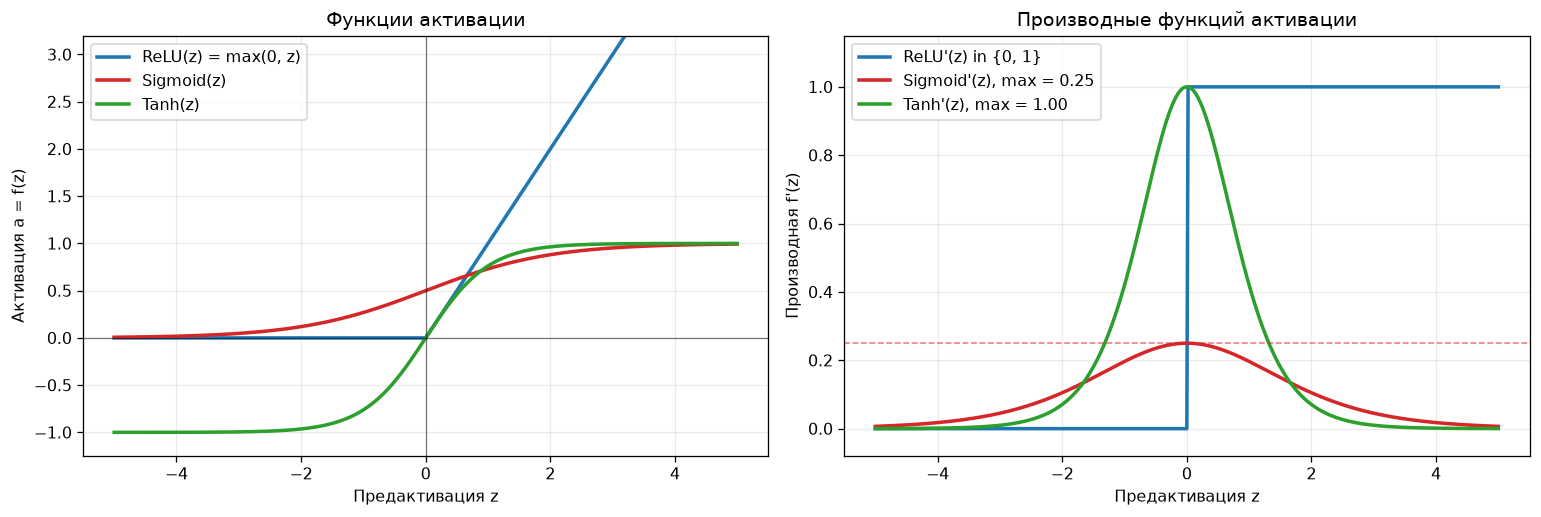

Применение ReLU к Z1 (shape=(5, 6)): занулено 17 из 30 элементов (56.7%)


,h_0,h_1,h_2,h_3,h_4,h_5
sample_0,0.0000,0.000,0.7095,0.5228,0.0000,0.0000
sample_1,0.0150,0.225,0.0000,0.0000,0.0000,0.5617
sample_2,0.0000,0.000,0.4995,0.6366,0.0000,0.0000
sample_3,0.7296,0.000,0.1705,0.3233,1.8893,0.0000
sample_4,0.0000,0.000,0.3832,0.2990,0.0000,0.0000


In [3]:
def relu(z: np.ndarray) -> np.ndarray:
    return np.maximum(0.0, z)


def relu_grad(z: np.ndarray) -> np.ndarray:
    return (z > 0.0).astype(float)


def sigmoid(z: np.ndarray) -> np.ndarray:
    # Численно устойчивая ветвящаяся реализация без переполнения exp(-z) при z << 0
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    exp_z = np.exp(z[~pos])
    out[~pos] = exp_z / (1.0 + exp_z)
    return out


def sigmoid_grad(z: np.ndarray) -> np.ndarray:
    s = sigmoid(z)
    return s * (1.0 - s)


def tanh_fn(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)


def tanh_grad(z: np.ndarray) -> np.ndarray:
    return 1.0 - np.tanh(z) ** 2


z_grid = np.linspace(-5.0, 5.0, 501)
assert np.allclose(sigmoid(z_grid), sp_special.expit(z_grid), atol=1e-15)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

axes[0].plot(z_grid, relu(z_grid), label="ReLU(z) = max(0, z)", lw=2.2, color="#1f77b4")
axes[0].plot(z_grid, sigmoid(z_grid), label="Sigmoid(z)", lw=2.2, color="#d62728")
axes[0].plot(z_grid, tanh_fn(z_grid), label="Tanh(z)", lw=2.2, color="#2ca02c")
axes[0].axhline(0.0, color="black", lw=0.8, alpha=0.5)
axes[0].axvline(0.0, color="black", lw=0.8, alpha=0.5)
axes[0].set_ylim(-1.25, 3.2)
axes[0].set_title("Функции активации")
axes[0].set_xlabel("Предактивация z")
axes[0].set_ylabel("Активация a = f(z)")
axes[0].legend(loc="upper left")

axes[1].plot(z_grid, relu_grad(z_grid), label="ReLU'(z) in {0, 1}", lw=2.2, color="#1f77b4")
axes[1].plot(z_grid, sigmoid_grad(z_grid), label="Sigmoid'(z), max = 0.25", lw=2.2, color="#d62728")
axes[1].plot(z_grid, tanh_grad(z_grid), label="Tanh'(z), max = 1.00", lw=2.2, color="#2ca02c")
axes[1].axhline(0.25, color="#d62728", lw=1.0, ls="--", alpha=0.6)
axes[1].set_ylim(-0.08, 1.15)
axes[1].set_title("Производные функций активации")
axes[1].set_xlabel("Предактивация z")
axes[1].set_ylabel("Производная f'(z)")
axes[1].legend(loc="upper left")

fig.tight_layout()
plt.show()

# Применяем ReLU к нашему батчу Z1
A1 = relu(Z1)
num_zeroed = int(np.sum(Z1 <= 0.0))
print(f"Применение ReLU к Z1 (shape={Z1.shape}): занулено {num_zeroed} из {Z1.size} элементов ({100.0 * num_zeroed / Z1.size:.1f}%)")
assert num_zeroed == 17 and Z1.size == 30
display(pd.DataFrame(A1, index=[f"sample_{i}" for i in range(B)], columns=[f"h_{h}" for h in range(H)]).round(4))

### Доказательство коллапса линейных слоёв без активации

Если убрать нелинейность между слоями и положить $A_1^{\text{lin}} = Z_1 = X W_1 + b_1$, композиция двух аффинных отображений по ассоциативности матричного умножения сворачивается в **один** линейный слой размера `4 -> 3`:

$$\text{logits}_{\text{no-act}} = (X W_1 + b_1) W_2 + b_2 = X \underbrace{(W_1 W_2)}_{W_{\text{eff}} \in \mathbb{R}^{4 \times 3}} + \underbrace{(b_1 W_2 + b_2)}_{b_{\text{eff}} \in \mathbb{R}^{3}}$$

Сколько бы таких линейных слоёв мы ни наслоили (`10` или `100`), без нелинейной активации сеть остаётся линейным классификатором с плоскими разделяющими гиперплоскостями, а `51` параметр нашей архитектуры избыточно кодирует всего `4 * 3 + 3 = 15` эффективных коэффициентов.

In [4]:
# 1. Алгебраическая и численная проверка линейного коллапса на случайной выборке из 200 точек в R^4
rng_check = np.random.default_rng(123)
X_test_collapse = rng_check.normal(0.0, 1.5, size=(200, D))

logits_two_linear_layers = (X_test_collapse @ W1 + b1) @ W2 + b2
W_eff = W1 @ W2          # shape (4, 3)
b_eff = b1 @ W2 + b2     # shape (3,)
logits_collapsed_single = X_test_collapse @ W_eff + b_eff

max_diff_linear = float(np.max(np.abs(logits_two_linear_layers - logits_collapsed_single)))
assert W_eff.shape == (4, 3) and b_eff.shape == (3,)
assert np.allclose(logits_two_linear_layers, logits_collapsed_single, atol=1e-14)

# 2. Сравнение с сетью с ReLU: проверяем, существует ли единая матрица (W_fit, b_fit), воспроизводящая ReLU-выход
logits_with_relu = relu(X_test_collapse @ W1 + b1) @ W2 + b2
X_aug = np.hstack([X_test_collapse, np.ones((len(X_test_collapse), 1))])
theta_best_linear, _, _, _ = np.linalg.lstsq(X_aug, logits_with_relu, rcond=None)
logits_best_linear_approx = X_aug @ theta_best_linear
max_residual_relu = float(np.max(np.abs(logits_with_relu - logits_best_linear_approx)))

print(f"Эффективные параметры без активации: W_eff.shape={W_eff.shape}, b_eff.shape={b_eff.shape} (15 параметров вместо 51)")
print(f"Макс. расхождение |(X @ W1 + b1) @ W2 + b2 - (X @ W_eff + b_eff)| на 200 объектах: {max_diff_linear:.2e}")
print(f"Макс. ошибка наилучшей линейной аппроксимации (МНК) для сети с ReLU:             {max_residual_relu:.4f} (>> 0 -> нелинейно!)")

Эффективные параметры без активации: W_eff.shape=(4, 3), b_eff.shape=(3,) (15 параметров вместо 51)
Макс. расхождение |(X @ W1 + b1) @ W2 + b2 - (X @ W_eff + b_eff)| на 200 объектах: 1.44e-15
Макс. ошибка наилучшей линейной аппроксимации (МНК) для сети с ReLU:             2.0603 (>> 0 -> нелинейно!)


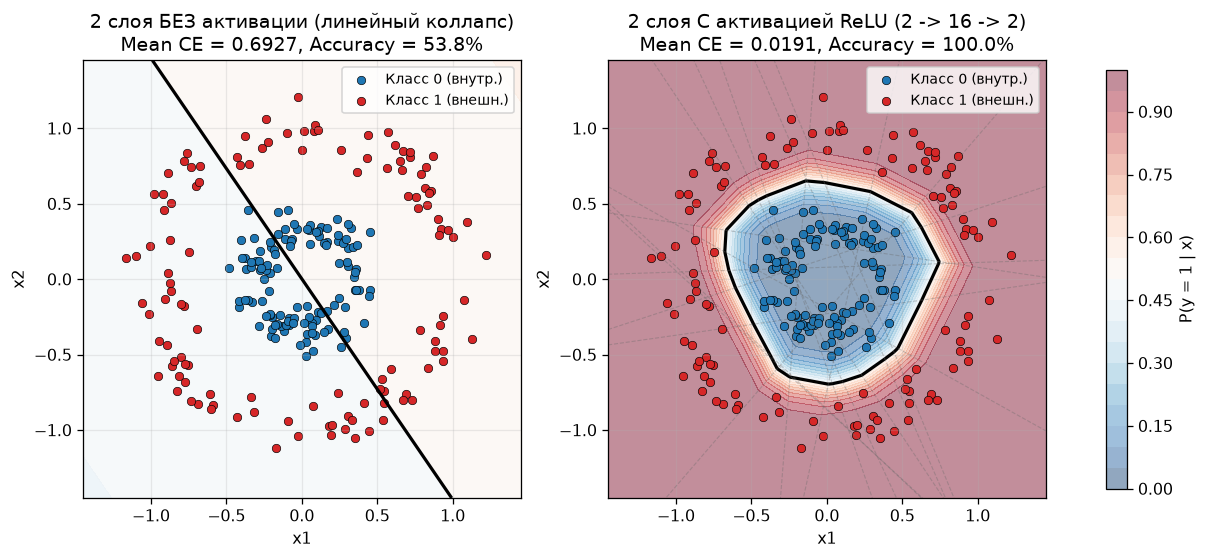

Без активации (2 -> 16 -> 2): Mean CE = 0.6927 (ln 2 = 0.6931), Accuracy = 53.75%
С ReLU        (2 -> 16 -> 2): Mean CE = 0.0191, Accuracy = 100.00% (замкнутый кусочно-линейный контур)


In [5]:
# 3. Наглядный 2D-эксперимент: концентрические кольца (2 -> 16 -> 2 без активации против ReLU)
rng_2d = np.random.default_rng(42)
n_per_class = 120
theta_inner = rng_2d.uniform(0.0, 2.0 * np.pi, size=n_per_class)
r_inner = rng_2d.normal(0.35, 0.08, size=n_per_class)
theta_outer = rng_2d.uniform(0.0, 2.0 * np.pi, size=n_per_class)
r_outer = rng_2d.normal(1.00, 0.10, size=n_per_class)

X_rings = np.vstack([
    np.column_stack([r_inner * np.cos(theta_inner), r_inner * np.sin(theta_inner)]),
    np.column_stack([r_outer * np.cos(theta_outer), r_outer * np.sin(theta_outer)]),
])
y_rings = np.array([0] * n_per_class + [1] * n_per_class)


def fit_2d_mlp(X_data: np.ndarray, y_data: np.ndarray, use_relu: bool, h_dim: int = 16, steps: int = 500, lr: float = 0.3):
    r_init = np.random.default_rng(42)
    w1 = r_init.normal(0.0, 1.0, size=(2, h_dim))
    b_1 = np.zeros(h_dim)
    w2 = r_init.normal(0.0, np.sqrt(2.0 / h_dim), size=(h_dim, 2))
    b_2 = np.zeros(2)
    one_hot_y = np.eye(2)[y_data]
    n_samples = len(y_data)

    for _ in range(steps):
        z1 = X_data @ w1 + b_1
        a1 = np.maximum(0.0, z1) if use_relu else z1
        lg = a1 @ w2 + b_2
        lg_shift = lg - np.max(lg, axis=1, keepdims=True)
        pr = np.exp(lg_shift) / np.sum(np.exp(lg_shift), axis=1, keepdims=True)

        dlg = (pr - one_hot_y) / n_samples
        dw2 = a1.T @ dlg
        db2 = np.sum(dlg, axis=0)
        da1 = dlg @ w2.T
        dz1 = da1 * (z1 > 0.0) if use_relu else da1
        dw1 = X_data.T @ dz1
        db1 = np.sum(dz1, axis=0)

        w1 -= lr * dw1
        b_1 -= lr * db1
        w2 -= lr * dw2
        b_2 -= lr * db2

    return w1, b_1, w2, b_2


def predict_2d_prob(grid_pts: np.ndarray, params: tuple, use_relu: bool) -> np.ndarray:
    w1, b_1, w2, b_2 = params
    z1 = grid_pts @ w1 + b_1
    a1 = np.maximum(0.0, z1) if use_relu else z1
    lg = a1 @ w2 + b_2
    lg_shift = lg - np.max(lg, axis=1, keepdims=True)
    return np.exp(lg_shift) / np.sum(np.exp(lg_shift), axis=1, keepdims=True)


params_lin = fit_2d_mlp(X_rings, y_rings, use_relu=False)
params_relu = fit_2d_mlp(X_rings, y_rings, use_relu=True)

probs_rings_lin = predict_2d_prob(X_rings, params_lin, use_relu=False)
probs_rings_relu = predict_2d_prob(X_rings, params_relu, use_relu=True)

ce_rings_lin = float(-np.mean(np.log(probs_rings_lin[np.arange(len(y_rings)), y_rings])))
acc_rings_lin = float(np.mean(np.argmax(probs_rings_lin, axis=1) == y_rings))
ce_rings_relu = float(-np.mean(np.log(probs_rings_relu[np.arange(len(y_rings)), y_rings])))
acc_rings_relu = float(np.mean(np.argmax(probs_rings_relu, axis=1) == y_rings))

gx, gy = np.meshgrid(np.linspace(-1.45, 1.45, 260), np.linspace(-1.45, 1.45, 260))
grid_flat = np.column_stack([gx.ravel(), gy.ravel()])
zz_lin = predict_2d_prob(grid_flat, params_lin, use_relu=False)[:, 1].reshape(gx.shape)
zz_relu = predict_2d_prob(grid_flat, params_relu, use_relu=True)[:, 1].reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
titles = [
    f"2 слоя БЕЗ активации (линейный коллапс)\nMean CE = {ce_rings_lin:.4f}, Accuracy = {100 * acc_rings_lin:.1f}%",
    f"2 слоя С активацией ReLU (2 -> 16 -> 2)\nMean CE = {ce_rings_relu:.4f}, Accuracy = {100 * acc_rings_relu:.1f}%",
]

for ax, zz, title in zip(axes, [zz_lin, zz_relu], titles):
    cf = ax.contourf(gx, gy, zz, levels=np.linspace(0.0, 1.0, 21), cmap="RdBu_r", alpha=0.45)
    ax.contour(gx, gy, zz, levels=[0.5], colors="black", linewidths=2.0)
    ax.scatter(X_rings[y_rings == 0, 0], X_rings[y_rings == 0, 1], c="#1f77b4", edgecolors="k", s=28, lw=0.4, label="Класс 0 (внутр.)")
    ax.scatter(X_rings[y_rings == 1, 0], X_rings[y_rings == 1, 1], c="#d62728", edgecolors="k", s=28, lw=0.4, label="Класс 1 (внешн.)")
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper right", fontsize=8.5)

# На правом графике тонким пунктиром покажем линии излома скрытых ReLU-нейронов (z_{1,k} = 0)
w1_r, b1_r, _, _ = params_relu
x_line = np.linspace(-1.45, 1.45, 200)
for k in range(w1_r.shape[1]):
    if abs(w1_r[1, k]) > 1e-6:
        y_line = -(w1_r[0, k] * x_line + b1_r[k]) / w1_r[1, k]
        axes[1].plot(x_line, y_line, ls="--", lw=0.7, color="dimgray", alpha=0.35)

fig.colorbar(cf, ax=axes.ravel().tolist(), shrink=0.86, label="P(y = 1 | x)")
plt.show()

print(f"Без активации (2 -> 16 -> 2): Mean CE = {ce_rings_lin:.4f} (ln 2 = {np.log(2):.4f}), Accuracy = {100 * acc_rings_lin:.2f}%")
print(f"С ReLU        (2 -> 16 -> 2): Mean CE = {ce_rings_relu:.4f}, Accuracy = {100 * acc_rings_relu:.2f}% (замкнутый кусочно-линейный контур)")

---
## 4. Forward pass до `logits` и численно устойчивый `Softmax`

На втором линейном слое скрытые представления $A_1 \in \mathbb{R}^{5 \times 6}$ преобразуются в некалиброванные оценки классов (`logits`) $Z_2 = A_1 W_2 + b_2 \in \mathbb{R}^{5 \times 3}$. Логиты могут принимать произвольные вещественные значения на $(-\infty, +\infty)$, а их сумма по строке не равна единице.

Чтобы перевести строку логитов $z \in \mathbb{R}^{C}$ в корректное распределение вероятностей $p \in \Delta^{C-1}$, используется `Softmax`:

$$p_c = \frac{e^{z_c}}{\sum_{k=0}^{C-1} e^{z_k}} = \frac{e^{z_c - m}}{\sum_{k=0}^{C-1} e^{z_k - m}}, \qquad m = \max_{0 \le k < C} z_k$$

Вычитание построчного максимума $m$ не меняет дробь (числитель и знаменатель делятся на $e^{m} > 0$), но гарантирует, что все показатели экспонент неположительны ($z_c - m \le 0$), полностью устраняя переполнение `exp(z) -> inf` в `float64` (порог переполнения `np.exp(709.78)`), а в знаменателе остаётся хотя бы одно слагаемое $e^{0} = 1$.

In [6]:
def naive_softmax(logits_arr: np.ndarray) -> np.ndarray:
    exp_z = np.exp(logits_arr)
    return exp_z / np.sum(exp_z, axis=-1, keepdims=True)


def stable_softmax(logits_arr: np.ndarray) -> np.ndarray:
    shifted = logits_arr - np.max(logits_arr, axis=-1, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / np.sum(exp_shifted, axis=-1, keepdims=True)


# 1. Демонстрация переполнения наивного Softmax на больших логитах
z_extreme = np.array([[1000.0, 1001.0, 999.0]])
with np.errstate(over="ignore", invalid="ignore"):
    naive_extreme = naive_softmax(z_extreme)
stable_extreme = stable_softmax(z_extreme)

assert np.all(np.isnan(naive_extreme)), "Ожидался NaN из-за inf / inf в naive_softmax"
assert np.allclose(stable_extreme, sp_special.softmax(z_extreme, axis=-1), atol=1e-15)

print("Проверка численной устойчивости на z_extreme = [[1000.0, 1001.0, 999.0]]:")
print(f"  naive_softmax(z_extreme)  = {naive_extreme}  <-- exp(1000) -> inf, inf/inf -> nan")
print(f"  stable_softmax(z_extreme) = {np.round(stable_extreme, 6)}, сумма = {stable_extreme.sum():.6f}\n")

# 2. Вычисляем logits и probs на нашем базовом батче
logits = A1 @ W2 + b2
probs = stable_softmax(logits)
row_sums = probs.sum(axis=1)

assert logits.shape == (5, 3) and probs.shape == (5, 3)
assert np.allclose(probs, sp_special.softmax(logits, axis=-1), atol=1e-15)
assert np.allclose(row_sums, np.ones(B), atol=1e-15)

y_pred_init = np.argmax(probs, axis=1)
forward_df = pd.DataFrame({
    "y_true": y_true,
    "y_pred": y_pred_init,
    "logit_0": logits[:, 0],
    "logit_1": logits[:, 1],
    "logit_2": logits[:, 2],
    "prob_0": probs[:, 0],
    "prob_1": probs[:, 1],
    "prob_2": probs[:, 2],
    "sum_probs": row_sums,
}, index=[f"sample_{i}" for i in range(B)])

print("Результаты прямого прохода (logits и вероятности Softmax по всем 5 объектам):")
display(forward_df.round(4))
print(f"Проверка сумм вероятностей по строкам: {row_sums}")
print(f"Разбор объекта sample_3 (y_true={y_true[3]}): logits={np.round(logits[3], 4)}, probs={np.round(probs[3], 4)}")

Проверка численной устойчивости на z_extreme = [[1000.0, 1001.0, 999.0]]:
  naive_softmax(z_extreme)  = [[nan nan nan]]  <-- exp(1000) -> inf, inf/inf -> nan
  stable_softmax(z_extreme) = [[0.2447 0.6652 0.09  ]], сумма = 1.000000

Результаты прямого прохода (logits и вероятности Softmax по всем 5 объектам):


,y_true,y_pred,logit_0,logit_1,logit_2,prob_0,prob_1,prob_2,sum_probs
sample_0,0,1,0.0713,0.0732,-0.8159,0.4143,0.4151,0.1706,1.0
sample_1,2,0,0.4061,-0.5231,-0.0955,0.4999,0.1974,0.3027,1.0
sample_2,1,0,0.0140,-0.0384,-0.6765,0.4081,0.3873,0.2046,1.0
sample_3,0,1,-0.2526,1.7195,-0.8742,0.1146,0.8238,0.0616,1.0
sample_4,2,0,0.0583,0.0119,-0.4470,0.3909,0.3732,0.2359,1.0


Проверка сумм вероятностей по строкам: [1. 1. 1. 1. 1.]
Разбор объекта sample_3 (y_true=0): logits=[-0.2526  1.7195 -0.8742], probs=[0.1146 0.8238 0.0616]


---
## 5. Функция потерь `Cross-Entropy`, `LogSumExp` и почему нельзя подавать `Softmax` в `CrossEntropyLoss`

Для объекта $i$ с истинной меткой $y_i \in \{0, \dots, C-1\}$ кросс-энтропия штрафует модель за малую вероятность правильного класса:

$$\ell_i = -\ln p_{i, y_i} = -z_{i, y_i} + m_i + \ln \sum_{c=0}^{C-1} e^{z_{i, c} - m_i}, \qquad m_i = \max_{c} z_{i, c}, \qquad \mathcal{L} = \frac{1}{B} \sum_{i=0}^{B-1} \ell_i$$

Ориентиром для некалиброванной или необученной модели на `C = 3` классах служит равномерное угадывание $p = (1/3, 1/3, 1/3)$, дающее потерю $-\ln(1/3) = \ln 3 \approx 1.0986$. Если средние потери выше $\ln 3$, сеть не просто не знает ответа, но и избыточно уверена в неверных классах.

**Почему в фреймворках (`PyTorch nn.CrossEntropyLoss`, `nn.BCEWithLogitsLoss`) на вход подаются сырые `logits`, а не выход `Softmax` / `Sigmoid`:**
1. **Защита от `underflow` при взятии логарифма:** если логит правильного класса сильно отрицателен (например, $z = [-1000, 0, 0]$ при $y=0$), то в `float64` вероятность `stable_softmax(z)[0]` схлопывается в точный машинный ноль (`0.0`, так как $e^{-1000} < 5 \cdot 10^{-324}$), и $-\ln(0.0)$ превращается в `inf`. Формула через `LogSumExp` сокращает $\ln$ и $\exp$ аналитически и возвращает конечное число $1000 + \ln 2 \approx 1000.6931$.
2. **Исключение ошибочного двойного `Softmax`:** если применить `Softmax` в конце модели, а затем передать полученные вероятности $p \in [0, 1]$ в `CrossEntropyLoss` (внутри которого уже встроен `log_softmax`), `Softmax` применится повторно к узкому отрезку $[0, 1]$. Даже при идеальной уверенности сети $p = [1, 0, 0]$ повторный `Softmax` выдаст $\frac{e^1}{e^1 + e^0 + e^0} = \frac{e}{e + 2} \approx 0.5761$, а минимально возможный `loss` навсегда застрянет на отметке $-\ln(0.5761) \approx 0.5514$ вместо $0.0$.

In [7]:
def cross_entropy_from_probs(probs_arr: np.ndarray, y: np.ndarray) -> np.ndarray:
    return -np.log(probs_arr[np.arange(len(y)), y])


def logsumexp(logits_arr: np.ndarray) -> np.ndarray:
    m = np.max(logits_arr, axis=-1, keepdims=True)
    return np.squeeze(m, axis=-1) + np.log(np.sum(np.exp(logits_arr - m), axis=-1))


def cross_entropy_from_logits(logits_arr: np.ndarray, y: np.ndarray) -> np.ndarray:
    true_logits = logits_arr[np.arange(len(y)), y]
    return -true_logits + logsumexp(logits_arr)


def bce_with_logits(z: np.ndarray, y: np.ndarray) -> np.ndarray:
    # Устойчивая бинарная кросс-энтропия: max(z, 0) - z*y + ln(1 + exp(-|z|))
    return np.maximum(z, 0.0) - z * y + np.log1p(np.exp(-np.abs(z)))


# 1. Расчёт потерь на базовом батче двумя способами и сверка со scipy.special.log_softmax
sample_losses_prob = cross_entropy_from_probs(probs, y_true)
sample_losses = cross_entropy_from_logits(logits, y_true)
scipy_ref_losses = -sp_special.log_softmax(logits, axis=-1)[np.arange(B), y_true]

assert np.allclose(sample_losses_prob, sample_losses, atol=1e-15)
assert np.allclose(sample_losses, scipy_ref_losses, atol=1e-15)

mean_loss = float(np.mean(sample_losses))
uniform_baseline = float(np.log(C))
assert np.isclose(mean_loss, 1.327039, atol=1e-5)
assert np.isclose(sample_losses[3], 2.165886, atol=1e-5)

ce_table = pd.DataFrame({
    "y_true": y_true,
    "p_true": probs[np.arange(B), y_true],
    "CE (-ln p_true)": sample_losses_prob,
    "CE (из logits / LogSumExp)": sample_losses,
    "Превышение над ln(3)": sample_losses - uniform_baseline,
}, index=[f"sample_{i}" for i in range(B)])

print(f"Равномерное случайное угадывание (p = 1/3): CE = ln(3) = {uniform_baseline:.4f}")
print(f"Средний Cross-Entropy по батчу (до обучения):            {mean_loss:.4f} (выше ln(3) из-за уверенных ошибок, особенно sample_3)\n")
display(ce_table.round(4))

# 2. Причина А: численный underflow при сильно отрицательном логите правильного класса
z_underflow = np.array([[-1000.0, 0.0, 0.0]])
y_underflow = np.array([0])
p_underflow = stable_softmax(z_underflow)
with np.errstate(divide="ignore"):
    loss_via_probs_underflow = cross_entropy_from_probs(p_underflow, y_underflow)[0]
loss_via_lse_underflow = cross_entropy_from_logits(z_underflow, y_underflow)[0]
assert np.isinf(loss_via_probs_underflow) and np.isclose(loss_via_lse_underflow, 1000.0 + np.log(2.0), atol=1e-12)

print("Демонстрация А (численный underflow на z = [-1000.0, 0.0, 0.0], y = 0):")
print(f"  stable_softmax(z)[0, 0]            = {p_underflow[0, 0]} (схлопывание exp(-1000) в 0.0)")
print(f"  -np.log(probs[0, 0])               = {loss_via_probs_underflow}  <-- потеря градиента и inf")
print(f"  cross_entropy_from_logits(z, y)[0] = {loss_via_lse_underflow:.6f}  (= 1000 + ln(2), точно!)\n")

# 3. Причина Б: ошибочный двойной Softmax (подача probs вместо logits в CrossEntropyLoss)
ideal_one_hot_probs = np.array([[1.0, 0.0, 0.0]])
double_softmax_probs = stable_softmax(ideal_one_hot_probs)
min_possible_double_ce = cross_entropy_from_logits(ideal_one_hot_probs, np.array([0]))[0]
wrong_batch_double_ce = float(np.mean(cross_entropy_from_logits(probs, y_true)))
assert np.isclose(double_softmax_probs[0, 0], np.e / (np.e + 2.0), atol=1e-15)
assert np.isclose(min_possible_double_ce, 0.5514447, atol=1e-6)

print("Демонстрация Б (ошибочный двойной Softmax — подача probs вместо logits):")
print(f"  Повторный Softmax от идеального [1, 0, 0]: {np.round(double_softmax_probs[0], 4)} (макс. вероятность падает до e/(e+2) = {double_softmax_probs[0,0]:.4f})")
print(f"  Минимально достижимый loss при двойном Softmax: {min_possible_double_ce:.4f} (вместо 0.0000!)")
print(f"  Искажённый Mean CE на нашем батче при двойном Softmax: {wrong_batch_double_ce:.4f} вместо истинного {mean_loss:.4f}\n")

# 4. Проверка устойчивой формулы BCEWithLogits для бинарной классификации
z_bin_moderate = np.array([-3.5, -0.7, 0.0, 1.2, 4.0])
y_bin_moderate = np.array([0.0, 1.0, 1.0, 0.0, 1.0])
p_sig = sigmoid(z_bin_moderate)
bce_naive = -(y_bin_moderate * np.log(p_sig) + (1.0 - y_bin_moderate) * np.log(1.0 - p_sig))
bce_stable = bce_with_logits(z_bin_moderate, y_bin_moderate)
assert np.allclose(bce_naive, bce_stable, atol=1e-15)

z_bin_extreme = np.array([-1000.0])
y_bin_extreme = np.array([1.0])
bce_extreme_val = bce_with_logits(z_bin_extreme, y_bin_extreme)[0]
assert np.isclose(bce_extreme_val, 1000.0, atol=1e-12)
print(f"Проверка BCEWithLogits: совпадение на умеренных z (max |diff| = {np.max(np.abs(bce_naive - bce_stable)):.2e}); при z=-1000, y=1 -> loss = {bce_extreme_val:.1f}")

Равномерное случайное угадывание (p = 1/3): CE = ln(3) = 1.0986
Средний Cross-Entropy по батчу (до обучения):            1.3270 (выше ln(3) из-за уверенных ошибок, особенно sample_3)



,y_true,p_true,CE (-ln p_true),CE (из logits / LogSumExp),Превышение над ln(3)
sample_0,0,0.4143,0.8812,0.8812,-0.2174
sample_1,2,0.3027,1.1950,1.1950,0.0964
sample_2,1,0.3873,0.9486,0.9486,-0.1500
sample_3,0,0.1146,2.1659,2.1659,1.0673
sample_4,2,0.2359,1.4445,1.4445,0.3459


Демонстрация А (численный underflow на z = [-1000.0, 0.0, 0.0], y = 0):
  stable_softmax(z)[0, 0]            = 0.0 (схлопывание exp(-1000) в 0.0)
  -np.log(probs[0, 0])               = inf  <-- потеря градиента и inf
  cross_entropy_from_logits(z, y)[0] = 1000.693147  (= 1000 + ln(2), точно!)

Демонстрация Б (ошибочный двойной Softmax — подача probs вместо logits):
  Повторный Softmax от идеального [1, 0, 0]: [0.5761 0.2119 0.2119] (макс. вероятность падает до e/(e+2) = 0.5761)
  Минимально достижимый loss при двойном Softmax: 0.5514 (вместо 0.0000!)
  Искажённый Mean CE на нашем батче при двойном Softmax: 1.1580 вместо истинного 1.3270

Проверка BCEWithLogits: совпадение на умеренных z (max |diff| = 4.44e-16); при z=-1000, y=1 -> loss = 1000.0


---
## 6. Таблица `shape` всех промежуточных тензоров и типичные ошибки размерностей

При проектировании и отладке нейронных сетей главный инвариант матричного умножения $(M, K) \times (K, N) \to (M, N)$ должен выполняться на каждом стыке слоёв, а ось батча `B` обязана сохраняться неизменной от входа `X (B, D)` до векторных потерь `sample_losses (B,)`. Сведём все `13` тензоров нашего прямого прохода в единую диагностическую таблицу и проверим, какую ошибку возбуждает `NumPy` при перепутанных осях матрицы весов.

In [8]:
mean_loss_arr = np.array(mean_loss)
tensor_specs = [
    ("X", "Входной батч признаков", X, "(B, D)"),
    ("W1", "Веса скрытого слоя", W1, "(D, H)"),
    ("b1", "Сдвиг скрытого слоя", b1, "(H,)"),
    ("X @ W1", "Линейная проекция без сдвига", XW1, "(B, H)"),
    ("Z1", "X @ W1 + b1", Z1, "(B, H)"),
    ("A1", "ReLU(Z1)", A1, "(B, H)"),
    ("W2", "Веса выходного слоя", W2, "(H, C)"),
    ("b2", "Сдвиг выходного слоя", b2, "(C,)"),
    ("logits", "A1 @ W2 + b2", logits, "(B, C)"),
    ("probs", "stable_softmax(logits)", probs, "(B, C)"),
    ("y_true", "Целевые индексы классов", y_true, "(B,)"),
    ("sample_losses", "cross_entropy_from_logits(logits, y_true)", sample_losses, "(B,)"),
    ("mean_loss", "np.mean(sample_losses)", mean_loss_arr, "()"),
]

shape_df = pd.DataFrame([
    {
        "Тензор": name,
        "Формула": formula,
        "Shape": str(arr.shape),
        "Символическая форма": sym_shape,
        "ndim": arr.ndim,
        "Элементов": arr.size,
        "Min": round(float(np.min(arr)), 4),
        "Max": round(float(np.max(arr)), 4),
    }
    for name, formula, arr, sym_shape in tensor_specs
])

display(shape_df)

# Демонстрация типичной ошибки размерностей: инициализация W1 в форме (H, D) = (6, 4) вместо (D, H) = (4, 6)
W1_wrong = np.zeros((6, 4))
try:
    _ = X @ W1_wrong
except ValueError as exc:
    caught_msg = str(exc)
    print(f"Перехвачен ожидаемый ValueError при умножении X {X.shape} @ W1_wrong {W1_wrong.shape}:")
    print(f"  -> {caught_msg}")
    print("  Диагностика: внутренняя ось X равна D=4, а ось 0 матрицы W1_wrong равна 6 (требуется транспонирование или форма (4, 6)).")

,Тензор,Формула,Shape,Символическая форма,ndim,Элементов,Min,Max
0,X,Входной батч признаков,"(5, 4)","(B, D)",2,20,-1.9500,1.1300
1,W1,Веса скрытого слоя,"(4, 6)","(D, H)",2,24,-0.5000,1.2800
2,b1,Сдвиг скрытого слоя,"(6,)","(H,)",1,6,-0.1000,0.1500
3,X @ W1,Линейная проекция без сдвига,"(5, 6)","(B, H)",2,30,-1.8444,1.7393
4,Z1,X @ W1 + b1,"(5, 6)","(B, H)",2,30,-1.7944,1.8893
5,A1,ReLU(Z1),"(5, 6)","(B, H)",2,30,0.0000,1.8893
6,W2,Веса выходного слоя,"(6, 3)","(H, C)",2,18,-1.0100,0.9000
7,b2,Сдвиг выходного слоя,"(3,)","(C,)",1,3,-0.0500,0.0500
8,logits,A1 @ W2 + b2,"(5, 3)","(B, C)",2,15,-0.8742,1.7195
9,probs,stable_softmax(logits),"(5, 3)","(B, C)",2,15,0.0616,0.8238


Перехвачен ожидаемый ValueError при умножении X (5, 4) @ W1_wrong (6, 4):
  -> matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 6 is different from 4)
  Диагностика: внутренняя ось X равна D=4, а ось 0 матрицы W1_wrong равна 6 (требуется транспонирование или форма (4, 6)).


---
## 7. Эксперимент с изменением весов: как меняются `logits`, вероятности и `Cross-Entropy`

Проследим, как изменение матриц весов управляет логитами, остротой распределения `Softmax` и величиной потерь `Cross-Entropy`. Для направленного улучшения весов выведем аналитические градиенты функции потерь $\mathcal{L} = \frac{1}{B} \sum_{i=0}^{B-1} \ell_i$ по цепному правилу (`backpropagation`):

$$\frac{\partial \mathcal{L}}{\partial \text{logits}} = \frac{1}{B}\bigl(\text{probs} - \operatorname{one\_hot}(y_{\text{true}})\bigr) \in \mathbb{R}^{B \times C}$$

$$\frac{\partial \mathcal{L}}{\partial W_2} = A_1^{\top} \frac{\partial \mathcal{L}}{\partial \text{logits}}, \quad
\frac{\partial \mathcal{L}}{\partial b_2} = \sum_{i=0}^{B-1} \left(\frac{\partial \mathcal{L}}{\partial \text{logits}}\right)_i, \quad
\frac{\partial \mathcal{L}}{\partial Z_1} = \left(\frac{\partial \mathcal{L}}{\partial \text{logits}} W_2^{\top}\right) \odot \mathbb{I}[Z_1 > 0], \quad
\frac{\partial \mathcal{L}}{\partial W_1} = X^{\top} \frac{\partial \mathcal{L}}{\partial Z_1}, \quad
\frac{\partial \mathcal{L}}{\partial b_1} = \sum_{i=0}^{B-1} \left(\frac{\partial \mathcal{L}}{\partial Z_1}\right)_i$$

Перед запуском экспериментов строго сверим все `51` аналитическую частную производную с численным градиентом по формуле центральных конечных разностей $\frac{\mathcal{L}(\theta + \varepsilon) - \mathcal{L}(\theta - \varepsilon)}{2\varepsilon}$ при $\varepsilon = 10^{-6}$.

In [9]:
def forward_and_loss(X_in: np.ndarray, y_in: np.ndarray, w1: np.ndarray, b_1: np.ndarray, w2: np.ndarray, b_2: np.ndarray) -> dict:
    z1 = X_in @ w1 + b_1
    a1 = relu(z1)
    lg = a1 @ w2 + b_2
    pr = stable_softmax(lg)
    losses = cross_entropy_from_logits(lg, y_in)
    preds = np.argmax(pr, axis=1)
    return {
        "Z1": z1,
        "A1": a1,
        "logits": lg,
        "probs": pr,
        "sample_losses": losses,
        "mean_loss": float(np.mean(losses)),
        "accuracy": float(np.mean(preds == y_in)),
        "n_correct": int(np.sum(preds == y_in)),
        "preds": preds,
    }


def backward_grads(X_in: np.ndarray, y_in: np.ndarray, cache: dict, w2: np.ndarray) -> tuple:
    b_size = len(y_in)
    one_hot = np.eye(w2.shape[1])[y_in]
    dlogits = (cache["probs"] - one_hot) / b_size
    dw2 = cache["A1"].T @ dlogits
    db2 = np.sum(dlogits, axis=0)
    da1 = dlogits @ w2.T
    dz1 = da1 * (cache["Z1"] > 0.0)
    dw1 = X_in.T @ dz1
    db1 = np.sum(dz1, axis=0)
    return dw1, db1, dw2, db2


def numerical_grad_array(loss_fn, param: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    num_g = np.zeros_like(param, dtype=float)
    it = np.nditer(param, flags=["multi_index"], op_flags=["readwrite"])
    while not it.finished:
        idx = it.multi_index
        orig = float(param[idx])
        param[idx] = orig + eps
        loss_plus = loss_fn()
        param[idx] = orig - eps
        loss_minus = loss_fn()
        param[idx] = orig
        num_g[idx] = (loss_plus - loss_minus) / (2.0 * eps)
        it.iternext()
    return num_g


# 1. Верификация аналитических градиентов центральными конечными разностями (gradient check)
base_state = forward_and_loss(X, y_true, W1, b1, W2, b2)
dW1, db1_g, dW2, db2_g = backward_grads(X, y_true, base_state, W2)

W1_chk, b1_chk, W2_chk, b2_chk = W1.copy(), b1.copy(), W2.copy(), b2.copy()
eval_loss = lambda: forward_and_loss(X, y_true, W1_chk, b1_chk, W2_chk, b2_chk)["mean_loss"]

num_dW1 = numerical_grad_array(eval_loss, W1_chk)
num_db1 = numerical_grad_array(eval_loss, b1_chk)
num_dW2 = numerical_grad_array(eval_loss, W2_chk)
num_db2 = numerical_grad_array(eval_loss, b2_chk)

for name, ana_g, num_g in [("dW1", dW1, num_dW1), ("db1", db1_g, num_db1), ("dW2", dW2, num_dW2), ("db2", db2_g, num_db2)]:
    max_err = float(np.max(np.abs(ana_g - num_g)))
    assert np.allclose(ana_g, num_g, atol=1e-9), f"Несовпадение градиента {name}: {max_err}"
    print(f"Gradient check {name:3s} (shape={str(ana_g.shape):6s}): max |analytic - numeric| = {max_err:.2e} -> OK")

# 2. Сравниваем режимы весов на фиксированном батче (X, y_true)
# Режим 1: Исходные веса (seed=42)
state_init = base_state

# Режим 2: Ненаправленное масштабирование выходных весов в 3 раза (3 * W2, без смены знаков)
state_scaled_3w2 = forward_and_loss(X, y_true, W1, b1, 3.0 * W2, b2)
# Дополнительно проверим масштабирование обоих слоёв (3 * W1, 3 * W2)
state_scaled_both = forward_and_loss(X, y_true, 3.0 * W1, b1, 3.0 * W2, b2)

# Режим 3: 1 шаг антиградиента с lr = 0.5
lr = 0.5
state_step1 = forward_and_loss(
    X, y_true,
    W1 - lr * dW1, b1 - lr * db1_g,
    W2 - lr * dW2, b2 - lr * db2_g,
)

# Режим 4: Траектория градиентного спуска (отметим 25 шагов, шаг достижения 100% Accuracy и 100 шагов)
W1_gd, b1_gd, W2_gd, b2_gd = W1.copy(), b1.copy(), W2.copy(), b2.copy()
loss_history = [state_init["mean_loss"]]
acc_history = [state_init["accuracy"]]
state_step25 = None
first_full_acc_step = None

for step in range(1, 101):
    cur = forward_and_loss(X, y_true, W1_gd, b1_gd, W2_gd, b2_gd)
    gw1, gb1, gw2, gb2 = backward_grads(X, y_true, cur, W2_gd)
    W1_gd -= lr * gw1
    b1_gd -= lr * gb1
    W2_gd -= lr * gw2
    b2_gd -= lr * gb2

    nxt = forward_and_loss(X, y_true, W1_gd, b1_gd, W2_gd, b2_gd)
    loss_history.append(nxt["mean_loss"])
    acc_history.append(nxt["accuracy"])
    if step == 25:
        state_step25 = nxt
    if nxt["n_correct"] == B and first_full_acc_step is None:
        first_full_acc_step = (step, nxt["mean_loss"])

state_step100 = forward_and_loss(X, y_true, W1_gd, b1_gd, W2_gd, b2_gd)

assert np.isclose(state_step1["mean_loss"], 1.104989, atol=1e-5)
assert np.isclose(state_step1["probs"][3, 0], 0.254761, atol=1e-5)
assert np.isclose(state_step1["sample_losses"][3], 1.367428, atol=1e-5)

regimes = [
    ("1. Исходные веса (W1, W2, seed=42)", state_init),
    ("2. Масштабирование 3 * W2 (без смены знака)", state_scaled_3w2),
    ("3. 1 шаг антиградиента (lr = 0.5)", state_step1),
    ("4a. 25 шагов градиентного спуска (lr = 0.5)", state_step25),
    ("4b. 100 шагов градиентного спуска (lr = 0.5)", state_step100),
]

regime_df = pd.DataFrame([
    {
        "Режим весов": title,
        "Mean CE": round(st["mean_loss"], 4),
        "Изменение к исходному (%)": f"{100.0 * (st['mean_loss'] - state_init['mean_loss']) / state_init['mean_loss']:+.2f}%",
        "Accuracy": f"{st['n_correct']}/{B} ({100.0 * st['accuracy']:.0f}%)",
        "Предсказания": str(st["preds"].tolist()),
        "p_true (sample_3, y=0)": round(float(st["probs"][3, 0]), 4),
        "CE (sample_3)": round(float(st["sample_losses"][3]), 4),
    }
    for title, st in regimes
])

print("\nСводное сравнение режимов весов на батче X (5 объектов):")
display(regime_df)
print(f"Примечание: при одновременном масштабировании обоих слоёв (3*W1, 3*W2) Mean CE взлетает до {state_scaled_both['mean_loss']:.4f}.")
print(f"Первый шаг достижения 100% точности (5/5) при lr=0.5: шаг {first_full_acc_step[0]} (Mean CE = {first_full_acc_step[1]:.4f}).")

Gradient check dW1 (shape=(4, 6)): max |analytic - numeric| = 1.53e-10 -> OK
Gradient check db1 (shape=(6,)  ): max |analytic - numeric| = 1.49e-10 -> OK
Gradient check dW2 (shape=(6, 3)): max |analytic - numeric| = 1.60e-10 -> OK
Gradient check db2 (shape=(3,)  ): max |analytic - numeric| = 4.45e-11 -> OK

Сводное сравнение режимов весов на батче X (5 объектов):


,Режим весов,Mean CE,Изменение к исходному (%),Accuracy,Предсказания,"p_true (sample_3, y=0)",CE (sample_3)
0,"1. Исходные веса (W1, W2, seed=42)",1.3270,+0.00%,0/5 (0%),"[1, 0, 0, 1, 0]",0.1146,2.1659
1,2. Масштабирование 3 * W2 (без смены знака),2.3252,+75.22%,1/5 (20%),"[1, 0, 1, 1, 1]",0.0022,6.1187
2,3. 1 шаг антиградиента (lr = 0.5),1.1050,-16.73%,1/5 (20%),"[0, 0, 0, 1, 0]",0.2548,1.3674
3,4a. 25 шагов градиентного спуска (lr = 0.5),0.3949,-70.25%,4/5 (80%),"[0, 2, 0, 0, 2]",0.9372,0.0648
4,4b. 100 шагов градиентного спуска (lr = 0.5),0.1712,-87.10%,5/5 (100%),"[0, 2, 1, 0, 2]",0.9844,0.0158


Примечание: при одновременном масштабировании обоих слоёв (3*W1, 3*W2) Mean CE взлетает до 5.6766.
Первый шаг достижения 100% точности (5/5) при lr=0.5: шаг 53 (Mean CE = 0.2922).


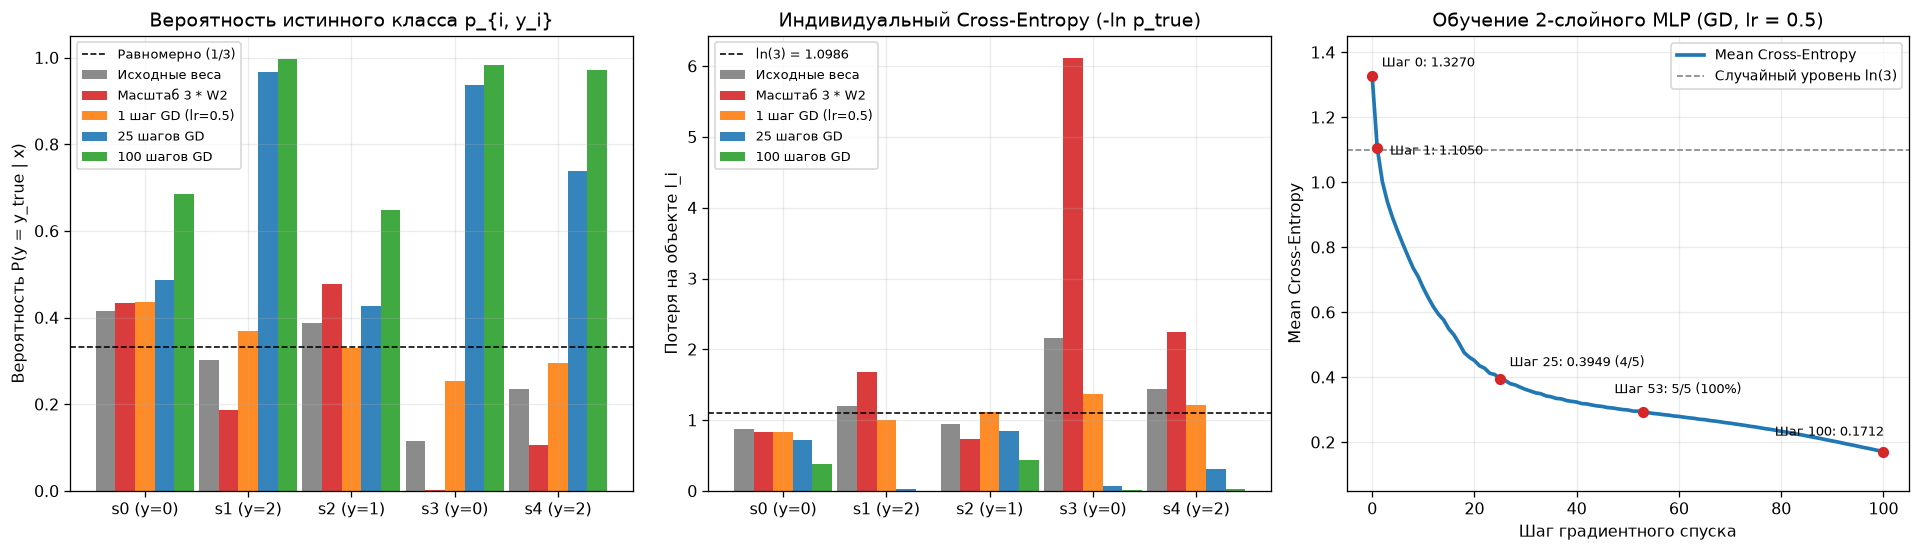

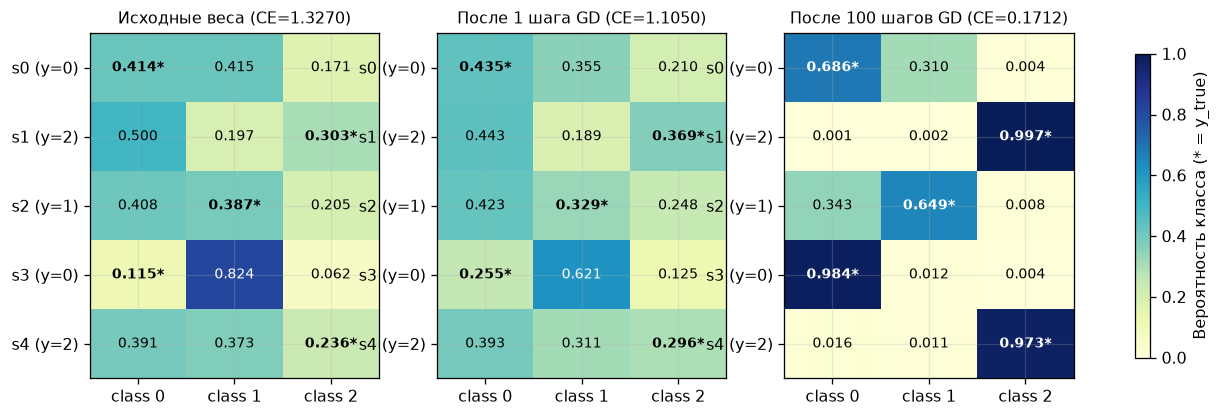

In [10]:
# Визуализация 1: Сравнение p_true, пообъектного Cross-Entropy и кривой обучения GD (1 x 3)
sample_labels = [f"s{i} (y={y_true[i]})" for i in range(B)]
x_idx = np.arange(B)
bar_w = 0.19

plot_regimes = [
    ("Исходные веса", state_init, "#7f7f7f"),
    ("Масштаб 3 * W2", state_scaled_3w2, "#d62728"),
    ("1 шаг GD (lr=0.5)", state_step1, "#ff7f0e"),
    ("25 шагов GD", state_step25, "#1f77b4"),
    ("100 шагов GD", state_step100, "#2ca02c"),
]

fig, axes = plt.subplots(1, 3, figsize=(16.8, 4.9))

# Панель 1: Вероятность истинного класса p_{i, y_i}
for k, (lbl, st, col) in enumerate(plot_regimes):
    p_true_vals = st["probs"][np.arange(B), y_true]
    axes[0].bar(x_idx + (k - 2) * bar_w, p_true_vals, width=bar_w, label=lbl, color=col, alpha=0.9)
axes[0].axhline(1.0 / C, color="black", ls="--", lw=1.0, label="Равномерно (1/3)")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(sample_labels)
axes[0].set_ylim(0.0, 1.05)
axes[0].set_title("Вероятность истинного класса p_{i, y_i}")
axes[0].set_ylabel("Вероятность P(y = y_true | x)")
axes[0].legend(fontsize=8, loc="upper left")

# Панель 2: Индивидуальные потери Cross-Entropy по объектам
for k, (lbl, st, col) in enumerate(plot_regimes):
    axes[1].bar(x_idx + (k - 2) * bar_w, st["sample_losses"], width=bar_w, label=lbl, color=col, alpha=0.9)
axes[1].axhline(np.log(C), color="black", ls="--", lw=1.0, label="ln(3) = 1.0986")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(sample_labels)
axes[1].set_title("Индивидуальный Cross-Entropy (-ln p_true)")
axes[1].set_ylabel("Потеря на объекте l_i")
axes[1].legend(fontsize=8, loc="upper left")

# Панель 3: Кривая убывания Mean Cross-Entropy по шагам градиентного спуска
steps_axis = np.arange(len(loss_history))
axes[2].plot(steps_axis, loss_history, lw=2.3, color="#1f77b4", label="Mean Cross-Entropy")
axes[2].axhline(np.log(C), color="gray", ls="--", lw=1.0, label="Случайный уровень ln(3)")

key_pts = [
    (0, loss_history[0], f"Шаг 0: {loss_history[0]:.4f}", (6, 6)),
    (1, loss_history[1], f"Шаг 1: {loss_history[1]:.4f}", (8, -4)),
    (25, loss_history[25], f"Шаг 25: {loss_history[25]:.4f} (4/5)", (6, 8)),
    (first_full_acc_step[0], first_full_acc_step[1], f"Шаг {first_full_acc_step[0]}: 5/5 (100%)", (-18, 12)),
    (100, loss_history[100], f"Шаг 100: {loss_history[100]:.4f}", (-68, 10)),
]
for st_i, val_i, txt_i, offset_xy in key_pts:
    axes[2].scatter([st_i], [val_i], color="#d62728", zorder=5, s=36)
    axes[2].annotate(txt_i, xy=(st_i, val_i), xytext=offset_xy, textcoords="offset points", fontsize=8.3)

axes[2].set_title("Обучение 2-слойного MLP (GD, lr = 0.5)")
axes[2].set_xlabel("Шаг градиентного спуска")
axes[2].set_ylabel("Mean Cross-Entropy")
axes[2].set_ylim(0.05, 1.45)
axes[2].legend(fontsize=8.5, loc="upper right")

fig.tight_layout()
plt.show()

# Визуализация 2: Тепловые карты матрицы вероятностей probs (5 x 3) в трёх состояниях сети
fig, axes = plt.subplots(1, 3, figsize=(13.8, 3.9))
heatmap_states = [
    (f"Исходные веса (CE={state_init['mean_loss']:.4f})", state_init["probs"]),
    (f"После 1 шага GD (CE={state_step1['mean_loss']:.4f})", state_step1["probs"]),
    (f"После 100 шагов GD (CE={state_step100['mean_loss']:.4f})", state_step100["probs"]),
]

for ax, (hm_title, p_mat) in zip(axes, heatmap_states):
    im = ax.imshow(p_mat, vmin=0.0, vmax=1.0, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(C))
    ax.set_xticklabels([f"class {c}" for c in range(C)])
    ax.set_yticks(range(B))
    ax.set_yticklabels([f"s{i} (y={y_true[i]})" for i in range(B)])
    ax.set_title(hm_title, fontsize=10)
    for r in range(B):
        for c in range(C):
            val = p_mat[r, c]
            mark = "*" if c == y_true[r] else ""
            txt_color = "white" if val > 0.58 else "black"
            ax.text(c, r, f"{val:.3f}{mark}", ha="center", va="center", color=txt_color, fontsize=8.8, fontweight="bold" if mark else "normal")

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.88, label="Вероятность класса (* = y_true)")
plt.show()

---
## 8. Итоговые выводы

1. **Что именно обучает нейронная сеть:**
   Сама архитектура задаёт лишь параметризованную композицию матричных умножений и нелинейностей, а вся «память» и разделяющая способность сети сосредоточены в обучаемых параметрах $\theta = \{W_1, b_1, W_2, b_2\}$ (в нашей сети `4 -> 6 -> 3` это ровно `51` вещественное число). Ненаправленное увеличение масштаба весов (`3 * W2`) не исправляет неверные знаки проекций, а лишь заостряет `Softmax`, поднимая `Mean Cross-Entropy` с `1.3270` до `2.3252` (на объекте `sample_3` ошибка вырастает с `2.1659` до `6.1187`). Обучение происходит только при направленном сдвиге весов вдоль антиградиента $-\nabla_{\theta}\mathcal{L}$: уже один шаг с `lr = 0.5` снижает потери на `16.73%` (`1.3270 -> 1.1050`), к `25`-му шагу доводит `Mean CE` до `0.3949` (`4/5`), на `53`-м шаге достигает `5/5 (100%)`, а к `100`-му шагу опускает потери до `0.1712`.

2. **Зачем между линейными слоями необходима нелинейная активация:**
   Без нелинейности произведение последовательных линейных слоёв алгебраически схлопывается в один линейный слой $(X W_1 + b_1) W_2 + b_2 = X W_{\text{eff}} + b_{\text{eff}}$ (`max |diff| < 1e-15`), сокращая `51` параметр до `15` эффективных коэффициентов и оставляя разделяющие границы плоскими гиперплоскостями (на концентрических кольцах точность застревает на `53.75%` при `Mean CE = 0.6927`). Добавление `ReLU` зануляет отрицательные предактивации (`17` из `30` элементов в базовом батче), создаёт изломы вдоль гиперплоскостей скрытых нейронов и позволяет аппроксимировать замкнутые нелинейные области (`100.00%` точности и `Mean CE = 0.0191` на тех же кольцах).

3. **Как связаны `logits`, `Softmax` и `Cross-Entropy`:**
   Выход последнего линейного слоя (`logits`) лежит на всей числовой прямой $(-\infty, +\infty)$ и отражает относительные голоса за классы. `Softmax` инвариантен к сдвигу на константу, поэтому вычитание $\max_c z_c$ защищает от переполнения `exp(1000) -> inf -> nan` и переводит логиты в вероятностный симплекс ($\sum_c p_c = 1$). `Cross-Entropy` равна $-\ln p_{y_{\text{true}}}$, но вычислять её следует напрямую из `logits` через `LogSumExp`: это устраняет как схлопывание малых вероятностей в машинный `0.0` (`-ln(0) -> inf` при $z = -1000$), так и грубую ошибку двойного `Softmax`, при которой минимально достижимые потери ограничиваются снизу числом `0.5514` вместо `0.0`.

4. **Почему контроль `shape` критичен при проектировании архитектуры:**
   В вычислительном графе нейросети соседние матрицы обязаны стыковаться по внутренним размерностям `(B, D) @ (D, H) -> (B, H) @ (H, C) -> (B, C)`, векторные сдвиги `b1 (H,)` и `b2 (C,)` корректно растягиваются по батчу только при совпадении правой оси, а ось батча `B` должна проходить сквозь сеть без искажений. Явная проверка `shape` промежуточных тензоров мгновенно отсекает как явные исключения `ValueError` (например, перепутанную форму `(6, 4)` вместо `(4, 6)`), так и гораздо более опасные тихие ошибки некорректного `broadcasting`.